In [1]:
import sys, warnings
sys.path.append("..")
warnings.filterwarnings("ignore")   # hides harmless convergence warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from arch import arch_model
from src.utils import evaluate_forecasts

df = pd.read_csv("../data/GSPC_processed.csv", index_col=0, parse_dates=True)
r = df["log_return"]
split = int(len(r) * 0.8)            # same split as notebooks 03 and 04

specs = {
    "GARCH(1,1)": dict(vol="GARCH", p=1, q=1),
    "EGARCH":     dict(vol="EGARCH", p=1, o=1, q=1),
    "GJR-GARCH":  dict(vol="GARCH", p=1, o=1, q=1),
}
REFIT_EVERY = 20                      # trading days between re-estimations

In [2]:
n = len(r)
parts = {name: [] for name in specs}

for i, s in enumerate(range(split, n, REFIT_EVERY)):
    e = min(s + REFIT_EVERY, n)
    for name, spec in specs.items():
        am = arch_model(r.iloc[:e], mean="Constant", dist="t", **spec)
        res = am.fit(last_obs=r.index[s - 1], disp="off")
        f = res.forecast(horizon=1, start=r.index[s - 1], reindex=False).variance["h.1"]
        parts[name].append(f.shift(1).loc[r.index[s:e]])
    if i % 10 == 0:
        print(f"refit block {i}, up to {r.index[s].date()}")

rolling = pd.DataFrame({f"{name} (rolling)": pd.concat(v) for name, v in parts.items()})
rolling.head()

refit block 0, up to 2023-06-06
refit block 10, up to 2024-03-22
refit block 20, up to 2025-01-08
refit block 30, up to 2025-10-27
refit block 40, up to 2026-08-14


,"GARCH(1,1) (rolling)",EGARCH (rolling),GJR-GARCH (rolling)
Date,,,
2023-06-06,0.832243,0.548946,0.451645
2023-06-07,0.709385,0.476879,0.402139
2023-06-08,0.644488,0.533935,0.421691
2023-06-09,0.600482,0.462263,0.377293
2023-06-12,0.515725,0.404406,0.340467


In [3]:
fixed = pd.read_csv("../data/garch_forecasts.csv", index_col=0, parse_dates=True)
fixed = fixed.rename(columns=lambda c: c if c.startswith("Rolling 21d") else f"{c} (fixed)")

all_fc = fixed.join(rolling, how="inner").dropna()
proxy = r.loc[all_fc.index] ** 2
evaluate_forecasts(proxy, all_fc).round(4)

,RMSE,MAE,QLIKE
GJR-GARCH (rolling),3.1104,0.9344,0.5788
GJR-GARCH (fixed),3.1085,0.9430,0.5829
EGARCH (rolling),3.1447,0.9030,0.5856
EGARCH (fixed),3.1395,0.9078,0.5882
"GARCH(1,1) (rolling)",3.3397,0.9974,0.6370
"GARCH(1,1) (fixed)",3.3483,1.0071,0.6408
Rolling 21d var,3.4695,1.0043,0.7476


In [4]:
from pathlib import Path
if Path("../data/lstm_forecasts.csv").exists():
    lstm = pd.read_csv("../data/lstm_forecasts.csv", index_col=0, parse_dates=True)["LSTM"]
    all_fc = all_fc.join(lstm, how="inner").dropna()
    proxy = r.loc[all_fc.index] ** 2
    print("LSTM included")
evaluate_forecasts(proxy, all_fc).round(4)

LSTM included


,RMSE,MAE,QLIKE
GJR-GARCH (rolling),3.1104,0.9344,0.5788
GJR-GARCH (fixed),3.1085,0.9430,0.5829
EGARCH (rolling),3.1447,0.9030,0.5856
EGARCH (fixed),3.1395,0.9078,0.5882
LSTM,3.3102,0.9352,0.6028
"GARCH(1,1) (rolling)",3.3397,0.9974,0.6370
"GARCH(1,1) (fixed)",3.3483,1.0071,0.6408
Rolling 21d var,3.4695,1.0043,0.7476


In [5]:
import statsmodels.api as sm

def dm_test(proxy, fa, fb, lags=5):
    fa, fb = fa.clip(lower=1e-8), fb.clip(lower=1e-8)
    d = ((np.log(fa) + proxy / fa) - (np.log(fb) + proxy / fb)).values
    res = sm.OLS(d, np.ones(len(d))).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
    return res.tvalues[0], res.pvalues[0]

names = list(all_fc.columns)
stat = pd.DataFrame(index=names, columns=names, dtype=float)
pval = pd.DataFrame(index=names, columns=names, dtype=float)
for a in names:
    for b in names:
        if a != b:
            stat.loc[a, b], pval.loc[a, b] = dm_test(proxy, all_fc[a], all_fc[b])

print("DM statistic (negative = ROW model has lower loss than COLUMN model)")
display(stat.round(2))
print("p-values (below 0.05 = difference is statistically significant)")
display(pval.round(3))

DM statistic (negative = ROW model has lower loss than COLUMN model)


,"GARCH(1,1) (fixed)",EGARCH (fixed),GJR-GARCH (fixed),Rolling 21d var,"GARCH(1,1) (rolling)",EGARCH (rolling),GJR-GARCH (rolling),LSTM
"GARCH(1,1) (fixed)",NaN,2.39,3.40,-2.47,2.17,2.50,3.78,1.37
EGARCH (fixed),-2.39,NaN,0.44,-3.12,-2.21,1.52,0.79,-0.42
GJR-GARCH (fixed),-3.40,-0.44,NaN,-3.34,-3.13,-0.22,2.42,-0.58
Rolling 21d var,2.47,3.12,3.34,NaN,2.53,3.13,3.40,2.48
"GARCH(1,1) (rolling)",-2.17,2.21,3.13,-2.53,NaN,2.33,3.51,1.30
EGARCH (rolling),-2.50,-1.52,0.22,-3.13,-2.33,NaN,0.56,-0.51
GJR-GARCH (rolling),-3.78,-0.79,-2.42,-3.40,-3.51,-0.56,NaN,-0.73
LSTM,-1.37,0.42,0.58,-2.48,-1.30,0.51,0.73,NaN


p-values (below 0.05 = difference is statistically significant)


,"GARCH(1,1) (fixed)",EGARCH (fixed),GJR-GARCH (fixed),Rolling 21d var,"GARCH(1,1) (rolling)",EGARCH (rolling),GJR-GARCH (rolling),LSTM
"GARCH(1,1) (fixed)",NaN,0.017,0.001,0.014,0.030,0.012,0.000,0.172
EGARCH (fixed),0.017,NaN,0.658,0.002,0.027,0.130,0.431,0.673
GJR-GARCH (fixed),0.001,0.658,NaN,0.001,0.002,0.827,0.016,0.561
Rolling 21d var,0.014,0.002,0.001,NaN,0.011,0.002,0.001,0.013
"GARCH(1,1) (rolling)",0.030,0.027,0.002,0.011,NaN,0.020,0.000,0.194
EGARCH (rolling),0.012,0.130,0.827,0.002,0.020,NaN,0.576,0.609
GJR-GARCH (rolling),0.000,0.431,0.016,0.001,0.000,0.576,NaN,0.465
LSTM,0.172,0.673,0.561,0.013,0.194,0.609,0.465,NaN


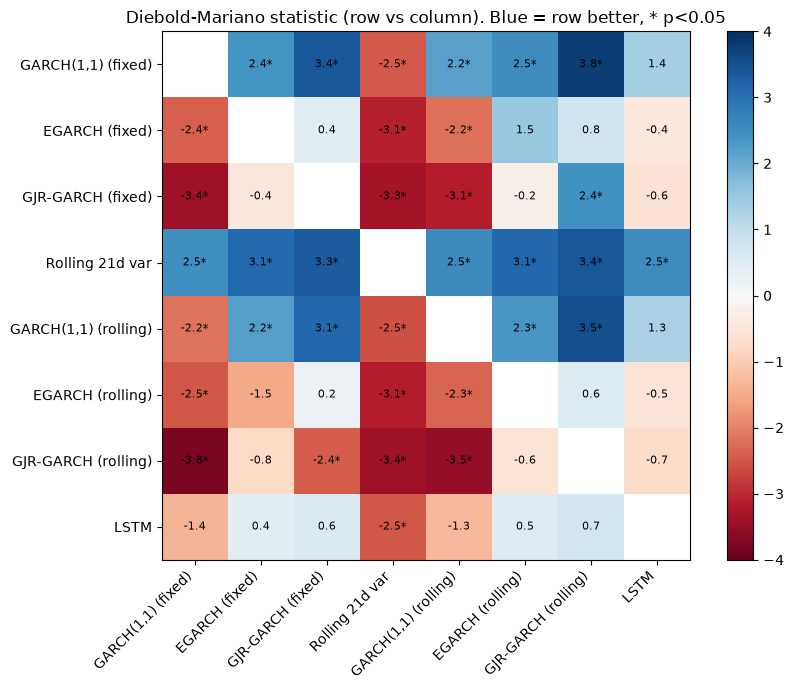

In [6]:
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(stat.values.astype(float), cmap="RdBu", vmin=-4, vmax=4)
ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=45, ha="right")
ax.set_yticks(range(len(names))); ax.set_yticklabels(names)
for i in range(len(names)):
    for j in range(len(names)):
        if i != j:
            star = "*" if pval.iloc[i, j] < 0.05 else ""
            ax.text(j, i, f"{stat.iloc[i, j]:.1f}{star}", ha="center", va="center", fontsize=8)
ax.set_title("Diebold-Mariano statistic (row vs column). Blue = row better, * p<0.05")
plt.colorbar(im); plt.tight_layout(); plt.show()

In [7]:
rolling.to_csv("../data/rolling_garch_forecasts.csv")